# Step0_intro_analysis - Two-Leg vs Concentric Windings: Equivalent Circuit and Leakage

![Two-leg model](Images/Step0_two_leg_model.png)

![Concentric model](Images/Step0_concentric_model.png)

![Step0_two_leg_open_circuit result](Images/Step0_two_leg_open_circuit_result_image.png)

![Step0_two_leg_short_circuit result](Images/Step0_two_leg_short_circuit_result_image.png)

![Step0_concentric_short_circuit result](Images/Step0_concentric_short_circuit_result_image.png)

The three field plots show |B| on the x = 0 cut plane at the phase where the primary current peaks. The two short-circuit plots share the same 0 ~ 1000 µT range (the core goes past it and shows up as solid red), so the leakage field in the window can be compared directly.

Square ferrite frame (100 mm cube with a 60 x 60 mm window, legs 20 x 100 mm, μr = 1800) with a 20-turn primary and a 10-turn secondary, every turn a separate copper loop, solved with EddyCurrent at 1 kHz. Three runs: an open-circuit and a short-circuit test with the secondary on the opposite leg (two-leg), and a short-circuit test with the secondary wound as a second layer on the same leg as the primary (concentric).

This notebook pulls the equivalent circuit out of the terminal results and checks every number against a hand calculation. Nothing came out more than a few percent off, so it's a light check without hypothesis sections. All predictions were written down before the matching CSV was opened (the short-circuit predictions do use numbers from the open-circuit run). Signs that depend on terminal polarity (k, V2, I2) were left out of the predictions.

$$\Lambda_1 = \frac{V_1}{\omega}, \qquad L_{11} = \frac{\mu_0 \mu_r N_1^2 A}{l}$$

$$L_{sc} = L_{11}\,(1-k^2), \qquad Z_{sc} = Z_{11} - \frac{Z_{12}^2}{Z_{22}}, \quad Z_{ij} = R_{ij} + j\omega L_{ij}$$

$$L_\sigma \approx \frac{\mu_0 N_1^2 \,\mathrm{MLT}}{h}\left(\frac{a_1}{3} + d + \frac{a_2}{3}\right)$$

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

# 1. Read the terminal CSVs exported by the three notebooks.
# Each column header carries its own unit (mV, mA, mOhm, ...) and complex values are written like "50 + 0i",
# so every value is converted to SI here.
UNIT_SCALE = {"": 1, "V": 1, "mV": 1e-3, "A": 1, "mA": 1e-3, "Wb": 1, "W": 1, "uW": 1e-6, "nW": 1e-9, "pW": 1e-12,
              "Ohm": 1, "mOhm": 1e-3, "uOhm": 1e-6, "H": 1, "mH": 1e-3, "uH": 1e-6, "kHz": 1e3}

def parse_value(text):
    text = str(text).replace(" ", "")
    if text.endswith("i"):
        return complex(text[:-1] + "j")
    return float(text)

def read_terminal_csv(path):
    raw = pd.read_csv(path)
    row = {}
    for col in raw.columns:
        name, unit = col.rsplit(" [", 1)
        row[name] = parse_value(raw[col].iloc[0]) * UNIT_SCALE[unit.rstrip("]")]
    return row

oc = read_terminal_csv("Step0_two_leg_open_circuit_terminal_data.csv")
sc = read_terminal_csv("Step0_two_leg_short_circuit_terminal_data.csv")
cc = read_terminal_csv("Step0_concentric_short_circuit_terminal_data.csv")

# Model values taken from the notebooks
mu0 = 4e-7 * np.pi
mu_r = 1800
N1, N2 = 20, 10
a = N1 / N2
A_leg = 20e-3 * 100e-3                    # leg cross-section (m^2)
sigma_cu = 5.8e7                          # copper conductivity (S/m)
wire_dia = (60 - 1) / 20 * 0.9 * 1e-3     # xsection_width, the hexagon's corner-to-corner width (m)
w = 2 * np.pi * oc["Freq"]

## Step0_two_leg_open_circuit - magnetizing inductance and turns ratio

Primary at 50 V, secondary open. The voltage is taken as a peak value. The inductance range comes from three magnetic path lengths around the window: inner corner 240 mm, mean 320 mm, outer 400 mm.

In [2]:
# 2. Open-circuit test: predictions vs FEM (predictions written down before the CSV was opened)
lam1 = abs(oc["FluxLinkage(Primary)"])
I1_oc = oc["Current(Primary)"]

pd.DataFrame({
    "Quantity": ["|Flux linkage| (mWb)", "Leg B (T)", "L11 (mH)", "|I1| (A)", "I1 phase vs V1 (deg)",
                 "|k|", "|V2| (V)", "Core loss (uW)"],
    "Prediction": ["7.96", "0.20", "4.5 ~ 7.5 (mean path 5.7)", "1.1 ~ 1.8", "about -90",
                   "0.90 ~ 0.98", "22.5 ~ 24.5", "order only (below a few W)"],
    "FEM": [lam1 * 1e3, lam1 / (N1 * A_leg), oc["Matrix1.L(Primary, Primary)"] * 1e3, abs(I1_oc),
            np.degrees(np.angle(I1_oc)), abs(oc["Matrix1.CplCoef(Primary, Secondary)"]),
            abs(oc["InducedVoltage(Secondary)"]), oc["CoreLoss"] * 1e6],
})

,Quantity,Prediction,FEM
0,|Flux linkage| (mWb),7.96,7.957751
1,Leg B (T),0.20,0.198944
2,L11 (mH),4.5 ~ 7.5 (mean path 5.7),6.457937
3,|I1| (A),1.1 ~ 1.8,1.232243
4,I1 phase vs V1 (deg),about -90,-89.971620
5,|k|,0.90 ~ 0.98,0.983767
6,|V2| (V),22.5 ~ 24.5,24.596403
7,Core loss (uW),order only (below a few W),233.483000


In [3]:
# 3. Open-circuit cross-checks computed from the geometry (done after the CSV was opened)
L11_oc = oc["Matrix1.L(Primary, Primary)"]
k_oc = abs(oc["Matrix1.CplCoef(Primary, Secondary)"])
l_eff = mu0 * mu_r * N1**2 * A_leg / L11_oc

# Primary resistance: 20 turns of 105 x 25 mm, hexagonal section with corner radius wire_dia/2
hex_area = 3 * np.sqrt(3) / 2 * (wire_dia / 2)**2
R1_geom = N1 * 2 * (105e-3 + 25e-3) / (sigma_cu * hex_area)
R1_fem = ((oc["InputVoltage(Primary)"] - oc["InducedVoltage(Primary)"]) / I1_oc).real

# Power balance and Steinmetz core loss (Cm f^x B^y, core volume 100^3 - 100 x 60 x 60 mm^3)
P_in = 0.5 * (oc["InputVoltage(Primary)"] * np.conj(I1_oc)).real
P_cu = 0.5 * abs(I1_oc)**2 * R1_fem
B_leg = lam1 / (N1 * A_leg)
P_core_steinmetz = 0.0016 * oc["Freq"]**1.3 * B_leg**2.1 * (1e6 - 100 * 60 * 60) * 1e-9

pd.DataFrame({
    "Check": ["Effective path length (mm)", "|V2| / (V1 N2/N1) vs |k|", "R1 (mOhm)", "Input power (mW)",
              "Core loss (uW)"],
    "Hand calculation": [f"240 / 320 / 400 (inner / mean / outer)", f"{k_oc:.5f} (|k|)", f"{R1_geom * 1e3:.3f} (hexagon wire)",
                         f"{(P_cu + oc['CoreLoss']) * 1e3:.3f} (copper + core)", f"{P_core_steinmetz * 1e6:.0f} (Steinmetz, uniform B)"],
    "FEM": [f"{l_eff * 1e3:.0f}", f"{abs(oc['InducedVoltage(Secondary)']) / (50 * N2 / N1):.5f}", f"{R1_fem * 1e3:.3f}",
            f"{P_in * 1e3:.3f}", f"{oc['CoreLoss'] * 1e6:.0f}"],
})

,Check,Hand calculation,FEM
0,Effective path length (mm),240 / 320 / 400 (inner / mean / outer),280
1,|V2| / (V1 N2/N1) vs |k|,0.98377 (|k|),0.98386
2,R1 (mOhm),19.582 (hexagon wire),19.570
3,Input power (mW),15.092 (copper + core),15.259
4,Core loss (uW),"274 (Steinmetz, uniform B)",233


## Step0_two_leg_short_circuit - leakage inductance and winding resistance

Secondary shorted (0 V solid winding), primary at 2 V. The predictions come from the open-circuit run: L_sc = L11(1 − k²) = 0.208 mH, R_eq = R1 + a²R2 with R2 = R1/2 (same wire, same turn shape). The ±5% band on L_sc is there because 1 − k² is only 0.032, so a 0.001 shift in k moves L_sc by about 6%.

This run used `PercentRefinement` 15 (30 in the open-circuit run), and the mutual resistance `Matrix1.R(Primary, Secondary)` was not exported.

In [4]:
# 4. Two-leg short-circuit test: predictions vs FEM
Z_sc = sc["InputVoltage(Primary)"] / sc["Current(Primary)"]

pd.DataFrame({
    "Quantity": ["L_sc (mH)", "R_eq (mOhm)", "|Z_sc| (Ohm)", "|I1| (A)", "I1 phase vs V1 (deg)", "|I2| (A)",
                 "Input power (mW)", "Core loss (uW)"],
    "Prediction": ["0.208 +/- 5%", "57.4 ~ 58.7", "1.308", "1.53", "about -87.5", "about 3.0",
                   "67 ~ 69", "far below 233 (open circuit)"],
    "FEM": [Z_sc.imag / w * 1e3, Z_sc.real * 1e3, abs(Z_sc), abs(sc["Current(Primary)"]),
            np.degrees(np.angle(sc["Current(Primary)"])), abs(sc["Current(Secondary)"]),
            0.5 * (sc["InputVoltage(Primary)"] * np.conj(sc["Current(Primary)"])).real * 1e3, sc["CoreLoss"] * 1e6],
})

,Quantity,Prediction,FEM
0,L_sc (mH),0.208 +/- 5%,0.203453
1,R_eq (mOhm),57.4 ~ 58.7,58.688128
2,|Z_sc| (Ohm),1.308,1.279681
3,|I1| (A),1.53,1.562889
4,I1 phase vs V1 (deg),about -87.5,-87.371406
5,|I2| (A),about 3.0,3.075884
6,Input power (mW),67 ~ 69,71.676479
7,Core loss (uW),far below 233 (open circuit),0.106306


In [5]:
# 5. Does the inductance matrix of the same run rebuild the terminal impedance?
def matrix_circuit(run, use_r12=True):
    R12 = run.get("Matrix1.R(Primary, Secondary)", 0.0) if use_r12 else 0.0
    Z11 = run["Matrix1.R(Primary, Primary)"] + 1j * w * run["Matrix1.L(Primary, Primary)"]
    Z22 = run["Matrix1.R(Secondary, Secondary)"] + 1j * w * run["Matrix1.L(Secondary, Secondary)"]
    Z12 = R12 + 1j * w * run["Matrix1.L(Primary, Secondary)"]
    return Z11 - Z12**2 / Z22

def copper_loss(run, use_r12=True):
    R12 = run.get("Matrix1.R(Primary, Secondary)", 0.0) if use_r12 else 0.0
    I1, I2 = run["Current(Primary)"], run["Current(Secondary)"]
    return 0.5 * (abs(I1)**2 * run["Matrix1.R(Primary, Primary)"] + abs(I2)**2 * run["Matrix1.R(Secondary, Secondary)"]
                  + 2 * R12 * (I1 * np.conj(I2)).real)

Z_sc_mat = matrix_circuit(sc)
M_sc, L22_sc, L11_sc = sc["Matrix1.L(Primary, Secondary)"], sc["Matrix1.L(Secondary, Secondary)"], sc["Matrix1.L(Primary, Primary)"]

pd.DataFrame({
    "Check": ["L_sc (mH)", "R_eq (mOhm)", "Input power vs matrix copper loss (mW)", "I2 / I1 vs M / L22",
              "N2 I2 / N1 I1 vs |k|", "L22 / L11 vs (N2/N1)^2"],
    "From matrix": [Z_sc_mat.imag / w * 1e3, Z_sc_mat.real * 1e3, copper_loss(sc) * 1e3, abs(M_sc / L22_sc),
                    abs(sc["Matrix1.CplCoef(Primary, Secondary)"]), L22_sc / L11_sc],
    "From terminals": [Z_sc.imag / w * 1e3, Z_sc.real * 1e3,
                       0.5 * (sc["InputVoltage(Primary)"] * np.conj(sc["Current(Primary)"])).real * 1e3,
                       abs(sc["Current(Secondary)"] / sc["Current(Primary)"]),
                       N2 * abs(sc["Current(Secondary)"]) / (N1 * abs(sc["Current(Primary)"])), (N2 / N1)**2],
})

,Check,From matrix,From terminals
0,L_sc (mH),0.203453,0.203453
1,R_eq (mOhm),58.406396,58.688128
2,Input power vs matrix copper loss (mW),71.332396,71.676479
3,I2 / I1 vs M / L22,1.968076,1.968076
4,N2 I2 / N1 I1 vs |k|,0.984117,0.984038
5,L22 / L11 vs (N2/N1)^2,0.250040,0.250000


## Step0_concentric_short_circuit - secondary moved onto the primary's leg

Same core and primary, but the 10-turn secondary sits on the same leg as a second layer, 5 mm outside the primary turn path (turn perimeter 300 mm instead of 260 mm). The primary voltage was lowered to 0.15 V to keep the current near 1.5 A. The leakage prediction uses the two-layer formula from the title cell with the window height h = 60 mm, MLT taken halfway between the layers, layer thickness a = one wire width, and d = the clear gap between the layers.

This run used `PercentRefinement` 15 and `MaximumPasses` 10 (20 passes went past the Student mesh limit), and the convergence table was not read, so it's not known whether the last pass reached the 1% energy error target.

In [6]:
# 6. Concentric short-circuit test: predictions vs FEM
MLT = 2 * ((100 + 2 * 5) + (20 + 2 * 5)) * 1e-3
gap = 5e-3 - wire_dia
L_sigma_formula = mu0 * N1**2 * MLT / 60e-3 * (wire_dia / 3 + gap + wire_dia / 3)

Z_cc = cc["InputVoltage(Primary)"] / cc["Current(Primary)"]
L_sc_two_leg = Z_sc.imag / w
L_sc_concentric = Z_cc.imag / w

pd.DataFrame({
    "Quantity": ["L_sc (uH)", "L_sc reduction vs two-leg (x)", "|k|", "R_eq (mOhm)", "|I1| (A)",
                 "I1 phase vs V1 (deg)", "R22 ratio to two-leg (perimeter 300/260 = 1.154)"],
    "Prediction": [f"{L_sigma_formula * 1e6:.1f} (7 ~ 15)", "21 (14 ~ 30)", "0.9993", "about 64",
                   "about 1.7 (1.35 ~ 1.95)", "about -43 (-33 ~ -55)", "1.154"],
    "FEM": [L_sc_concentric * 1e6, L_sc_two_leg / L_sc_concentric, abs(cc["Matrix1.CplCoef(Primary, Secondary)"]),
            Z_cc.real * 1e3, abs(cc["Current(Primary)"]), np.degrees(np.angle(cc["Current(Primary)"])),
            cc["Matrix1.R(Secondary, Secondary)"] / sc["Matrix1.R(Secondary, Secondary)"]],
})

,Quantity,Prediction,FEM
0,L_sc (uH),9.7 (7 ~ 15),10.890449
1,L_sc reduction vs two-leg (x),21 (14 ~ 30),18.681810
2,|k|,0.9993,0.999161
3,R_eq (mOhm),about 64,65.423668
4,|I1| (A),about 1.7 (1.35 ~ 1.95),1.584446
5,I1 phase vs V1 (deg),about -43 (-33 ~ -55),-46.285261
6,R22 ratio to two-leg (perimeter 300/260 = 1.154),1.154,1.159524


The two-leg run left a 0.5% gap between the terminal R_eq and the one rebuilt from the matrix diagonal. This run also exported the mutual resistance R12, which comes from the proximity loss each winding's current causes in the other winding's copper.

In [7]:
# 7. Matrix rebuild of the concentric run, with and without the mutual resistance R12
Z_cc_no_r12 = matrix_circuit(cc, use_r12=False)
Z_cc_r12 = matrix_circuit(cc, use_r12=True)
P_in_cc = 0.5 * (cc["InputVoltage(Primary)"] * np.conj(cc["Current(Primary)"])).real

pd.DataFrame({
    "Source": ["Terminals (V1 / I1)", "Matrix, R12 = 0", "Matrix, with R12"],
    "R_eq (mOhm)": [Z_cc.real * 1e3, Z_cc_no_r12.real * 1e3, Z_cc_r12.real * 1e3],
    "L_sc (uH)": [Z_cc.imag / w * 1e6, Z_cc_no_r12.imag / w * 1e6, Z_cc_r12.imag / w * 1e6],
    "Power (mW)": [P_in_cc * 1e3, copper_loss(cc, use_r12=False) * 1e3, copper_loss(cc) * 1e3],
})

,Source,R_eq (mOhm),L_sc (uH),Power (mW)
0,Terminals (V1 / I1),65.423668,10.890449,82.122027
1,"Matrix, R12 = 0",66.308876,10.890606,83.233171
2,"Matrix, with R12",65.423668,10.890449,82.122027


## Two-leg vs concentric - T-equivalent circuit

Both circuits are referred to the primary with a = N1/N2 = 2, using the matrix of each short-circuit run: Lm = a|M|, Ll1 = L11 − a|M|, Ll2' = a²L22 − a|M|, R2' = a²R22.

In [8]:
# 8. T-equivalent circuit of both winding layouts (from each short-circuit run's matrix)
def t_equivalent(run):
    L11, L22, M = run["Matrix1.L(Primary, Primary)"], run["Matrix1.L(Secondary, Secondary)"], abs(run["Matrix1.L(Primary, Secondary)"])
    return [run["Matrix1.R(Primary, Primary)"] * 1e3, a**2 * run["Matrix1.R(Secondary, Secondary)"] * 1e3,
            (L11 - a * M) * 1e6, (a**2 * L22 - a * M) * 1e6, a * M * 1e3, abs(run["Matrix1.CplCoef(Primary, Secondary)"])]

pd.DataFrame({"Two-leg": t_equivalent(sc), "Concentric": t_equivalent(cc)},
             index=["R1 (mOhm)", "R2' (mOhm)", "Ll1 (uH)", "Ll2' (uH)", "Lm (mH)", "|k|"])

,Two-leg,Concentric
R1 (mOhm),20.165200,20.577429
R2' (mOhm),39.491891,45.791777
Ll1 (uH),102.030438,6.617635
Ll2' (uH),103.061938,4.267598
Lm (mH),6.353739,6.478314
|k|,0.984117,0.999161


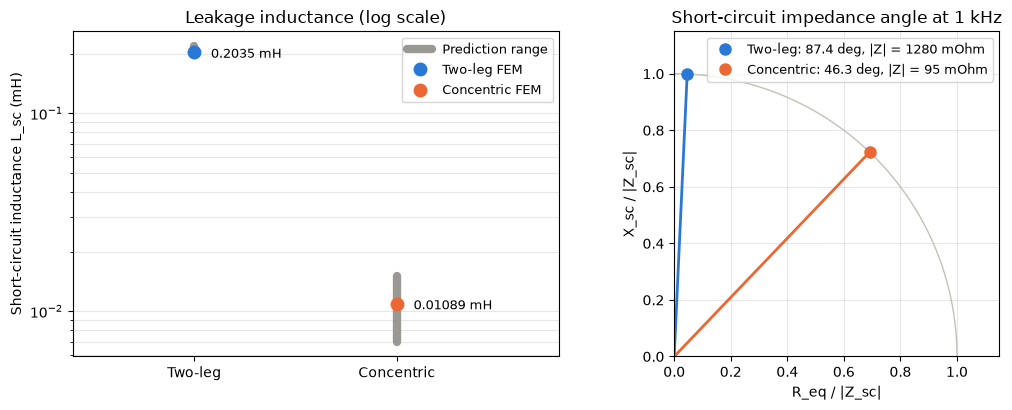

In [9]:
# 9. Leakage inductance and short-circuit impedance of both layouts
colors = {"Two-leg": "#2a78d6", "Concentric": "#eb6834"}
measured = {"Two-leg": Z_sc, "Concentric": Z_cc}
pred_range = {"Two-leg": (0.208 * 0.95, 0.208 * 1.05), "Concentric": (7e-3, 15e-3)}   # mH

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))

for i, name in enumerate(["Two-leg", "Concentric"]):
    lo, hi = pred_range[name]
    ax1.plot([i, i], [lo, hi], color="#9a9893", linewidth=6, solid_capstyle="round",
             label="Prediction range" if i == 0 else None)
    ax1.plot(i, measured[name].imag / w * 1e3, "o", markersize=9, color=colors[name], label=f"{name} FEM")
    ax1.annotate(f"{measured[name].imag / w * 1e3:.4g} mH", (i, measured[name].imag / w * 1e3),
                 textcoords="offset points", xytext=(12, -4), fontsize=9)
ax1.set_yscale("log")
ax1.set_xticks([0, 1], ["Two-leg", "Concentric"])
ax1.set_xlim(-0.6, 1.8)
ax1.set_ylabel("Short-circuit inductance L_sc (mH)")
ax1.set_title("Leakage inductance (log scale)")
ax1.grid(True, which="both", axis="y", alpha=0.3)
ax1.legend(fontsize=9, loc="upper right")

# Right panel: Z_sc scaled to unit length, so the angle between R_eq and X_sc is drawn true
theta = np.linspace(0, np.pi / 2, 100)
ax2.plot(np.cos(theta), np.sin(theta), color="#c3c2b7", linewidth=1)
for name, Z in measured.items():
    u = Z / abs(Z)
    ax2.plot([0, u.real], [0, u.imag], "-", linewidth=2, color=colors[name])
    ax2.plot(u.real, u.imag, "o", markersize=8, color=colors[name],
             label=f"{name}: {np.degrees(np.angle(Z)):.1f} deg, |Z| = {abs(Z) * 1e3:.0f} mOhm")
ax2.set_aspect("equal")
ax2.set_xlim(0, 1.15)
ax2.set_ylim(0, 1.15)
ax2.set_xlabel("R_eq / |Z_sc|")
ax2.set_ylabel("X_sc / |Z_sc|")
ax2.set_title("Short-circuit impedance angle at 1 kHz")
ax2.grid(True, alpha=0.3)
ax2.legend(fontsize=9, loc="upper right")

fig.tight_layout()
os.makedirs("Images", exist_ok=True)
plt.savefig("Images/Step0_intro_leakage_and_short_circuit_impedance.png", dpi=150, bbox_inches="tight")
plt.show()

## Conclusion

**Step0_two_leg_open_circuit.** Flux linkage, leg B, magnetizing current and |V2| all landed on the prediction. L11 = 6.46 mH sits inside the 4.5 ~ 7.5 mH band, and the effective path length it implies (about 280 mm) is between the inner corner and the mean path, closer to the inner one, since the flux crowds toward the short inner corner. |V2| falls short of 25 V by exactly the coupling factor (0.9839 vs |k| = 0.9838), which is what V2 = jωM·I1 says for an open secondary. |k| came out slightly above the predicted 0.90 ~ 0.98: with μr = 1800 the core holds the flux well enough that splitting the windings onto opposite legs only leaks about 1.6%. The primary resistance from the terminal voltages matches the hexagonal wire geometry within 0.1%, and the input power is almost all copper loss, with the ferrite core loss at 1 kHz and 0.2 T in the hundreds of µW. The Steinmetz estimate with a uniform B is about 18% above the FEM core loss; since the loss goes as B^2.1 it is sensitive to the uneven B around the corners, which is left as the likely cause.

**Step0_two_leg_short_circuit.** L_sc = 0.2035 mH is 2.2% below the open-circuit prediction, inside the ±5% band. The shift is just the 1 − k² sensitivity: k moved by +0.00035 between the two runs (different mesh setting and a solid instead of stranded secondary), and that alone accounts for it. The matrix of the same run rebuilds the terminal L_sc to six digits, the secondary current follows M/L22, and L22/L11 equals (N2/N1)², so the inductance matrix and the terminal results are consistent. R_eq and the input power are about 0.5% above the matrix diagonal; the concentric run below points to the mutual resistance R12 as the cause, but R12 was not exported here, so for this run it stays a strong candidate rather than a check.

**Step0_concentric_short_circuit.** Moving the secondary onto the primary's leg cut the leakage inductance from 203.5 µH to 10.9 µH, an 18.7x reduction (predicted 21x, range 14 ~ 30x), while |k| only went from 0.984 to 0.999. The two-layer formula gave 9.7 µH, 11% low; the formula assumes a uniform field across the gap confined by the window height, while more than half of each turn runs outside the core in open air and the windings are round wires rather than sheets, which is left as the likely reason. With the leakage this small, the short-circuit impedance changes character: the current lags by 46° instead of 87°, because the copper resistance is now about as large as the leakage reactance. In the T-equivalent table the concentric leakage splits unevenly between Ll1 and Ll2', but that split depends on choosing a = N1/N2 and only their sum L_sc is fixed by the test. Including R12 (221 µΩ, about 1% of R1) makes the matrix rebuild match the terminal impedance and the input power to nine digits, while leaving it out gives a 1.4% gap.

Overall, the open-circuit and short-circuit results give a complete and self-consistent equivalent circuit, and the comparison shows why commercial transformers wind both coils on the same leg: the coupling factor barely changes, but the leakage inductance, which sets the voltage drop under load, drops by more than an order of magnitude. R1 also came out 3 ~ 5% higher in the short-circuit runs (20.2 and 20.6 mΩ vs 19.6 mΩ) even though the primary is the same in all three; the different mesh settings are the likely cause (not checked), and it doesn't change any of the conclusions above. No further analysis is needed for this model.